# Gradient boosting: scikit-learn `GradientBoostingClassifier` and `HistGradientBoostingClassifier` (issue #10)

Follows the shared evaluation protocol (`src/common.py`, issue #8): development data = train + val, repeated stratified 5-fold CV x 3, seed 42, test set untouched.

**How tuning is scored.** With a weak signal (AUC about 0.69, fold std about 0.01), picking the best of many settings on the same folds and then reporting that fold score is optimistic. So tuned models are scored with **nested CV**: for each of the 15 outer folds the hyper-parameter search runs *only on that fold's training part*, and the model is scored on the held-out part. The logged tuned score is therefore an honest estimate of "tune, then deploy". The final parameters come from one more search on all dev data (saved to `results/best_params_sklearn.json` for #15 and #18).

In [1]:
import sys, json, time, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import loguniform, randint, uniform
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import GradientBoostingClassifier, HistGradientBoostingClassifier
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold, cross_validate
from sklearn.metrics import roc_auc_score

from src.common import (load_dev, load_train_val, evaluate, get_cv, log_result, _who,
                        SCORING, RANDOM_STATE, ROOT)
from datetime import date
warnings.filterwarnings('ignore')

X, y = load_dev()
print(X.shape, 'Needs Maintenance share:', round(y.mean(), 3))

(16604, 6) Needs Maintenance share: 0.631


## 1. Trivial baselines
The positive class is 63% of rows, so a model that always says "Needs Maintenance" already gets recall 1.0 and F1 0.77. Any model has to be judged against that, not against zero.

In [2]:
baselines = [
    evaluate(DummyClassifier(strategy='prior'), X, y, name='Dummy (class prior)',
             notes='trivial baseline: no signal, AUC 0.5'),
    evaluate(DummyClassifier(strategy='constant', constant=1), X, y, name='Dummy (always Needs Maintenance)',
             notes='trivial baseline: F1 reference'),
]
cols = ['model', 'cv_auc_mean', 'cv_pr_auc_mean', 'cv_f1_mean', 'cv_recall_mean', 'cv_precision_mean']
pd.DataFrame(baselines)[cols]

,model,cv_auc_mean,cv_pr_auc_mean,cv_f1_mean,cv_recall_mean,cv_precision_mean
0,Dummy (class prior),0.5,0.6305,0.7734,1.0,0.6305
1,Dummy (always Needs Maintenance),0.5,0.6305,0.7734,1.0,0.6305


## 2. Default settings (logged)

In [3]:
defaults = [
    evaluate(GradientBoostingClassifier(random_state=RANDOM_STATE), X, y,
             name='GradientBoosting (sklearn)', params={'defaults': True}),
    evaluate(HistGradientBoostingClassifier(random_state=RANDOM_STATE), X, y,
             name='HistGradientBoosting (sklearn)', params={'defaults': True}),
]
pd.DataFrame(defaults)[cols + ['fit_time_mean_s']]

,model,cv_auc_mean,cv_pr_auc_mean,cv_f1_mean,cv_recall_mean,cv_precision_mean,fit_time_mean_s
0,GradientBoosting (sklearn),0.7007,0.7977,0.7614,0.8409,0.6956,1.328
1,HistGradientBoosting (sklearn),0.6957,0.7950,0.7585,0.8367,0.6937,0.058


## 3. Tuning with nested CV

Search: `RandomizedSearchCV`, 25 random settings, inner 3-fold CV on the training part of each outer fold, scored by ROC AUC.

In [4]:
SPACES = {
    'GradientBoosting (sklearn)': (
        GradientBoostingClassifier(random_state=RANDOM_STATE),
        {'n_estimators': randint(100, 401), 'learning_rate': loguniform(0.01, 0.2),
         'max_depth': randint(2, 6), 'subsample': uniform(0.6, 0.4),
         'min_samples_leaf': randint(5, 101)}),
    'HistGradientBoosting (sklearn)': (
        HistGradientBoostingClassifier(random_state=RANDOM_STATE, early_stopping=True),
        {'max_iter': randint(100, 501), 'learning_rate': loguniform(0.01, 0.2),
         'max_leaf_nodes': randint(8, 64), 'min_samples_leaf': randint(10, 101),
         'l2_regularization': loguniform(1e-3, 10)}),
}
N_ITER, INNER_CV = 25, StratifiedKFold(3, shuffle=True, random_state=RANDOM_STATE)

def make_search(est, space, seed=RANDOM_STATE):
    return RandomizedSearchCV(est, space, n_iter=N_ITER, cv=INNER_CV, scoring='roc_auc',
                              random_state=seed, n_jobs=1, refit=True)

nested_rows, best_params = [], {}
for name, (est, space) in SPACES.items():
    t = time.time()
    res = cross_validate(make_search(est, space), X, y, cv=get_cv(), scoring=SCORING, n_jobs=-1)
    row = {'date': date.today().isoformat(), 'who': _who(), 'model': name + ' tuned', 'features': 'raw',
           'params': f'RandomizedSearchCV n_iter={N_ITER}', 'n_rows': len(X),
           'fit_time_mean_s': round(float(np.mean(res['fit_time'])), 1),
           'notes': 'NESTED CV (search inside each outer training fold); fit time includes the search'}
    for k in SCORING:
        row[f'cv_{k}_mean'] = round(float(np.mean(res[f'test_{k}'])), 4)
        row[f'cv_{k}_std'] = round(float(np.std(res[f'test_{k}'])), 4)
    log_result(row); nested_rows.append(row)
    # final parameters: one search on all dev data
    s = make_search(est, space).fit(X, y)
    best_params[name] = {k: (v.item() if hasattr(v, 'item') else v) for k, v in s.best_params_.items()}
    print(f'{name}: nested AUC {row["cv_auc_mean"]} +/- {row["cv_auc_std"]}  ({time.time()-t:.0f}s)  best: {best_params[name]}')

out = ROOT / 'results' / 'best_params_sklearn.json'
out.write_text(json.dumps(best_params, indent=2))

GradientBoosting (sklearn): nested AUC 0.702 +/- 0.0088  (366s)  best: {'learning_rate': 0.012502377950801122, 'max_depth': 4, 'min_samples_leaf': 13, 'n_estimators': 228, 'subsample': 0.679486272613669}


HistGradientBoosting (sklearn): nested AUC 0.7003 +/- 0.0092  (28s)  best: {'l2_regularization': 8.568869785189005, 'learning_rate': 0.040482984757722995, 'max_iter': 406, 'max_leaf_nodes': 14, 'min_samples_leaf': 30}


396

## 4. Summary

In [5]:
summary = pd.DataFrame(baselines + defaults + nested_rows)[cols + ['cv_auc_std', 'fit_time_mean_s']]
summary.round(4)

,model,cv_auc_mean,cv_pr_auc_mean,cv_f1_mean,cv_recall_mean,cv_precision_mean,cv_auc_std,fit_time_mean_s
0,Dummy (class prior),0.5000,0.6305,0.7734,1.0000,0.6305,0.0000,0.009
1,Dummy (always Needs Maintenance),0.5000,0.6305,0.7734,1.0000,0.6305,0.0000,0.001
2,GradientBoosting (sklearn),0.7007,0.7977,0.7614,0.8409,0.6956,0.0085,1.328
3,HistGradientBoosting (sklearn),0.6957,0.7950,0.7585,0.8367,0.6937,0.0100,0.058
4,GradientBoosting (sklearn) tuned,0.7020,0.7991,0.7642,0.8513,0.6933,0.0088,181.000
5,HistGradientBoosting (sklearn) tuned,0.7003,0.7977,0.7616,0.8382,0.6978,0.0092,7.400


## 5. Overfitting check

Train on the official `train` split, score on `val`, as trees are added (default learning rates, deliberately overfit-prone). A growing gap between the two curves means more trees only memorise noise.

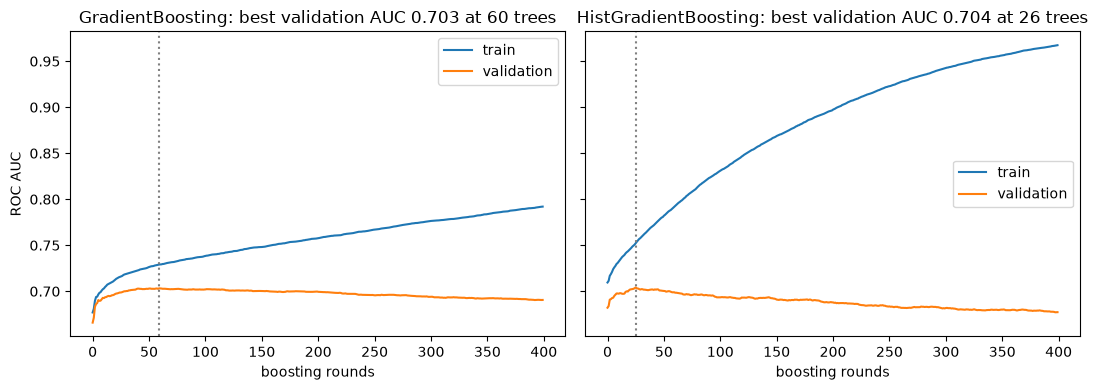

In [6]:
X_tr, y_tr, X_va, y_va = load_train_val()
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, (name, est) in zip(axes, [('GradientBoosting', GradientBoostingClassifier(n_estimators=400, random_state=RANDOM_STATE)),
                                   ('HistGradientBoosting', HistGradientBoostingClassifier(max_iter=400, early_stopping=False, random_state=RANDOM_STATE))]):
    est.fit(X_tr, y_tr)
    tr = [roc_auc_score(y_tr, p[:, 1]) for p in est.staged_predict_proba(X_tr)]
    va = [roc_auc_score(y_va, p[:, 1]) for p in est.staged_predict_proba(X_va)]
    ax.plot(tr, label='train'); ax.plot(va, label='validation')
    ax.axvline(int(np.argmax(va)), ls=':', c='gray'); ax.set_title(f'{name}: best validation AUC {max(va):.3f} at {int(np.argmax(va))+1} trees')
    ax.set_xlabel('boosting rounds'); ax.legend()
axes[0].set_ylabel('ROC AUC')
plt.tight_layout(); plt.savefig(ROOT / 'reports' / 'figures' / 'boosting_sklearn_overfit.png', dpi=130); plt.show()

## 6. Conclusions

In [7]:
best = summary.loc[summary.model.str.contains('tuned')].sort_values('cv_auc_mean', ascending=False).iloc[0]
dflt = summary.set_index('model').loc[['GradientBoosting (sklearn)', 'HistGradientBoosting (sklearn)'], 'cv_auc_mean']
print('Defaults AUC:', dflt.round(4).to_dict())
print('Best tuned (nested):', best.model, best.cv_auc_mean, '+/-', best.cv_auc_std)
print('Always-positive F1 reference:', summary.set_index('model').loc['Dummy (always Needs Maintenance)', 'cv_f1_mean'])

Defaults AUC: {'GradientBoosting (sklearn)': 0.7007, 'HistGradientBoosting (sklearn)': 0.6957}
Best tuned (nested): GradientBoosting (sklearn) tuned 0.702 +/- 0.0088
Always-positive F1 reference: 0.7734
